In [284]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Market data
import yfinance as yf

print("Libraries loaded successfully")

Libraries loaded successfully


In [285]:
# Pull XLE data
xle = yf.download("XLE", start="1998-01-01")

# Flatten columns if multi-index
if isinstance(xle.columns, pd.MultiIndex):
    xle.columns = xle.columns.get_level_values(0)

# Use Close price
xle = xle[["Close"]].rename(columns={"Close": "price"})

xle.head()

[*********************100%***********************]  1 of 1 completed


Price,price
Date,
1998-12-22,5.736629
1998-12-23,5.856063
1998-12-24,5.825242
1998-12-28,5.794419
1998-12-29,5.852208


In [286]:
# Daily returns
xle["return"] = xle["price"].pct_change()

# Monthly dataset
monthly = pd.DataFrame()
monthly["price"] = xle["price"].resample("ME").last()
monthly["return"] = np.log(monthly["price"]).diff()
monthly["volatility"] = xle["return"].resample("ME").std()

monthly.head()

,price,return,volatility
Date,,,
1998-12-31,5.755890,NaN,0.012785
1999-01-31,5.378333,-0.067845,0.012846
1999-02-28,5.332098,-0.008634,0.012807
1999-03-31,6.085907,0.132231,0.019360
1999-04-30,6.986804,0.138047,0.020290


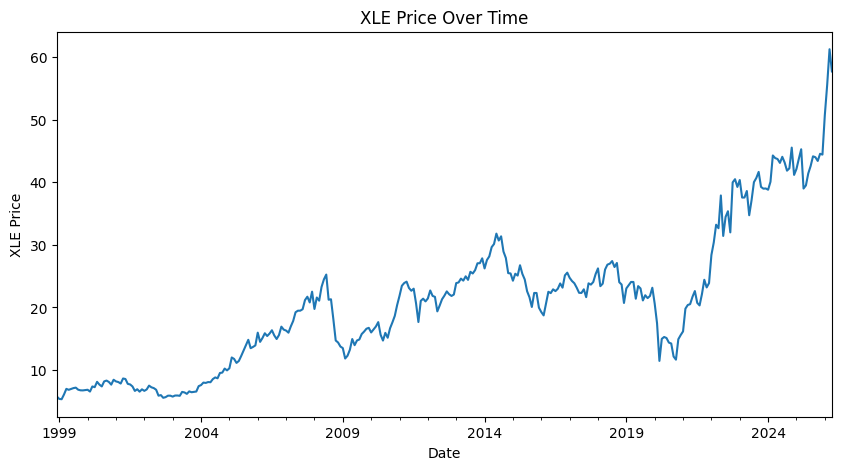

In [287]:
monthly["price"].plot(
    title="XLE Price Over Time",
    figsize=(10, 5)
)

plt.xlabel("Date")
plt.ylabel("XLE Price")
plt.show()

In [288]:
monthly.to_csv("../data/processed/xle_monthly.csv")

print("Saved monthly XLE dataset to data/processed/xle_monthly.csv")

Saved monthly XLE dataset to data/processed/xle_monthly.csv


In [289]:
# Reload clean copy
gpr = pd.read_excel("../data/raw/data_gpr_daily_recent.xls")

# Convert date column
gpr["date"] = pd.to_datetime(gpr["date"])

# Set index
gpr = gpr.set_index("date")

# Keep daily GPR index
gpr = gpr[["GPRD"]].rename(columns={"GPRD": "gpr"})

gpr.head()

,gpr
date,
1985-01-01,230.039429
1985-01-02,115.676971
1985-01-03,97.428459
1985-01-04,157.366638
1985-01-05,81.361313


In [290]:
gpr_monthly = gpr.resample("ME").mean()

gpr_monthly.head()

,gpr
date,
1985-01-31,102.877888
1985-02-28,116.861454
1985-03-31,124.430717
1985-04-30,88.570832
1985-05-31,101.942872


In [291]:
df = monthly.join(gpr_monthly, how="inner").dropna()

df.head()

,price,return,volatility,gpr
Date,,,,
1999-01-31,5.378333,-0.067845,0.012846,64.203600
1999-02-28,5.332098,-0.008634,0.012807,58.933004
1999-03-31,6.085907,0.132231,0.019360,82.753258
1999-04-30,6.986804,0.138047,0.020290,105.422438
1999-05-31,6.836010,-0.021819,0.016137,83.508795


In [292]:
X = sm.add_constant(df["gpr"])
y = df["return"]

model_return = sm.OLS(y, X).fit()
print(model_return.summary())

                            OLS Regression Results                            
Dep. Variable:                 return   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                  0.009311
Date:                Tue, 28 Apr 2026   Prob (F-statistic):              0.923
Time:                        21:22:31   Log-Likelihood:                 395.86
No. Observations:                 328   AIC:                            -787.7
Df Residuals:                     326   BIC:                            -780.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0062      0.009      0.668      0.5

In [293]:
X = sm.add_constant(df["gpr"])
y = df["volatility"]

model_volatility = sm.OLS(y, X).fit()
print(model_volatility.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     1.750
Date:                Tue, 28 Apr 2026   Prob (F-statistic):              0.187
Time:                        21:22:31   Log-Likelihood:                 1082.4
No. Observations:                 328   AIC:                            -2161.
Df Residuals:                     326   BIC:                            -2153.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0171      0.001     14.904      0.0

In [294]:
df["gpr_lag1"] = df["gpr"].shift(1)
df["gpr_lag2"] = df["gpr"].shift(2)

X = sm.add_constant(df[["gpr", "gpr_lag1", "gpr_lag2"]].dropna())
y = df.loc[X.index, "return"]

model_lag = sm.OLS(y, X).fit()
print(model_lag.summary())

                            OLS Regression Results                            
Dep. Variable:                 return   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.009
Method:                 Least Squares   F-statistic:                  0.004230
Date:                Tue, 28 Apr 2026   Prob (F-statistic):               1.00
Time:                        21:22:32   Log-Likelihood:                 393.01
No. Observations:                 326   AIC:                            -778.0
Df Residuals:                     322   BIC:                            -762.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0070      0.011      0.649      0.5

In [295]:
X = sm.add_constant(df[["gpr", "gpr_lag1", "gpr_lag2"]].dropna())
y = df.loc[X.index, "volatility"]

model_vol_lag = sm.OLS(y, X).fit()
print(model_vol_lag.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                    0.6841
Date:                Tue, 28 Apr 2026   Prob (F-statistic):              0.562
Time:                        21:22:32   Log-Likelihood:                 1075.0
No. Observations:                 326   AIC:                            -2142.
Df Residuals:                     322   BIC:                            -2127.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0175      0.001     13.120      0.0

In [296]:
wti = yf.download("CL=F", start="1998-01-01")

if isinstance(wti.columns, pd.MultiIndex):
    wti.columns = wti.columns.get_level_values(0)

wti = wti[["Close"]].rename(columns={"Close": "wti_price"})

wti_monthly = pd.DataFrame()
wti_monthly["wti_price"] = wti["wti_price"].resample("ME").last()
wti_monthly["wti_return"] = np.log(wti_monthly["wti_price"]).diff()

df = df.join(wti_monthly, how="inner")

[*********************100%***********************]  1 of 1 completed


In [297]:
X = sm.add_constant(df[["gpr", "wti_return"]].dropna())
y = df.loc[X.index, "return"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 return   R-squared:                       0.387
Model:                            OLS   Adj. R-squared:                  0.383
Method:                 Least Squares   F-statistic:                     96.15
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           4.19e-33
Time:                        21:22:32   Log-Likelihood:                 445.13
No. Observations:                 308   AIC:                            -884.3
Df Residuals:                     305   BIC:                            -873.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.008      0.091      0.9

<Axes: title={'center': 'XLE vs Oil Returns'}, xlabel='Date'>

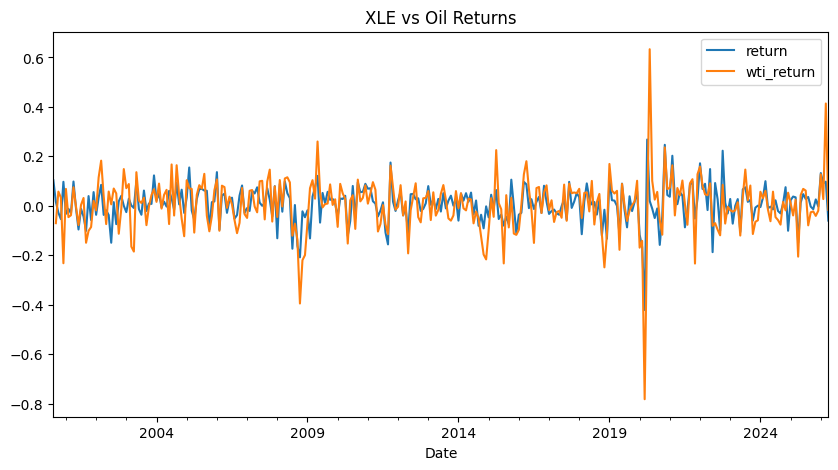

In [298]:
df[["return", "wti_return"]].plot(figsize=(10,5), title="XLE vs Oil Returns")

In [299]:
tickers = ["BP", "SHEL", "XOM", "CVX"]

data = yf.download(tickers, start="1998-01-01", group_by="ticker", auto_adjust=False)

prices = pd.DataFrame()

for ticker in tickers:
    prices[ticker] = data[ticker]["Close"]

prices.head()

[*********************100%***********************]  4 of 4 completed


,BP,SHEL,XOM,CVX
Date,,,,
1998-01-02,39.46875,55.625,30.93750,38.96875
1998-01-05,38.87500,54.313,30.59375,37.84375
1998-01-06,37.31250,52.125,29.50000,36.87500
1998-01-07,38.65625,53.500,30.43750,38.18750
1998-01-08,38.28125,52.250,29.78125,36.75000


In [300]:
monthly_prices = prices.resample("ME").last()
returns = np.log(monthly_prices).diff()

returns.head()

,BP,SHEL,XOM,CVX
Date,,,,
1998-01-31,NaN,NaN,NaN,NaN
1998-02-28,0.029143,0.058048,0.072149,0.078756
1998-03-31,0.040005,0.045002,0.059009,-0.006979
1998-04-30,0.093526,-0.005525,0.077338,0.029143
1998-05-31,-0.066304,-0.006659,-0.035703,-0.034606


In [301]:
returns.columns

Index(['BP', 'SHEL', 'XOM', 'CVX'], dtype='str')

In [302]:
df_multi = returns.merge(
    df[["gpr", "wti_return"]],
    left_index=True,
    right_index=True,
    how="inner"
)

df_multi = df_multi.dropna()

df_multi.head()

,BP,SHEL,XOM,CVX,gpr,wti_return
Date,,,,,,
2000-09-30,-0.041576,-0.020640,0.087538,0.008652,52.758094,-0.070072
2000-10-31,-0.039693,-0.009437,0.000876,-0.037346,74.846507,0.057608
2000-11-30,-0.071186,0.005258,-0.013404,-0.003049,45.440477,0.033392
2000-12-31,0.009180,0.014553,-0.012147,0.030818,46.011571,-0.232059
2001-01-31,0.072988,-0.003523,-0.032589,-0.013803,47.345442,0.068495


In [303]:
df_multi.columns

Index(['BP', 'SHEL', 'XOM', 'CVX', 'gpr', 'wti_return'], dtype='str')

In [304]:
results = {}

for stock in ["BP", "SHEL", "XOM", "CVX"]:
    X = sm.add_constant(df_multi[["gpr", "wti_return"]])
    y = df_multi[stock]

    model = sm.OLS(y, X).fit()
    results[stock] = model

    print(f"\n=== {stock} ===")
    print(model.summary())


=== BP ===
                            OLS Regression Results                            
Dep. Variable:                     BP   R-squared:                       0.268
Model:                            OLS   Adj. R-squared:                  0.263
Method:                 Least Squares   F-statistic:                     55.79
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           2.25e-21
Time:                        21:22:33   Log-Likelihood:                 411.03
No. Observations:                 308   AIC:                            -816.1
Df Residuals:                     305   BIC:                            -804.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0063      0.009     -0.

<Axes: title={'center': 'Oil Sensitivity by Company'}>

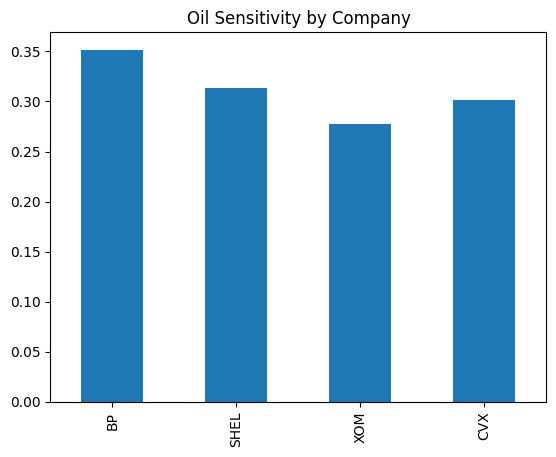

In [305]:
betas = {
    "BP": results["BP"].params["wti_return"],
    "SHEL": results["SHEL"].params["wti_return"],
    "XOM": results["XOM"].params["wti_return"],
    "CVX": results["CVX"].params["wti_return"]
}

pd.Series(betas).plot(kind="bar", title="Oil Sensitivity by Company")

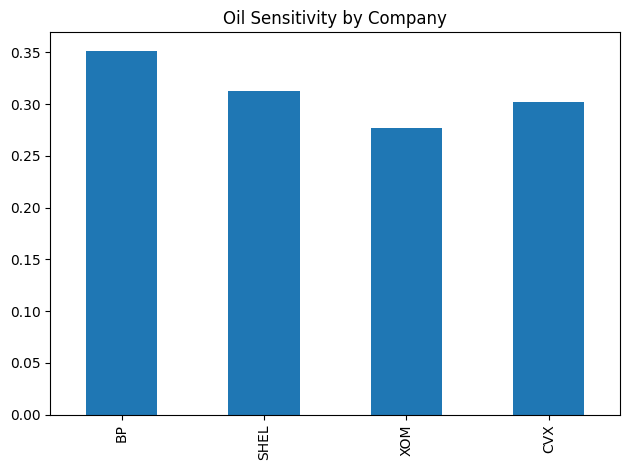

In [306]:
import matplotlib.pyplot as plt

pd.Series(betas).plot(kind="bar", title="Oil Sensitivity by Company")

plt.tight_layout()
plt.savefig("../outputs/charts/oil_betas.png")
plt.show()

In [307]:
# Define extreme geopolitical events (top 5%)
threshold = df["gpr"].quantile(0.95)
df["high_gpr"] = (df["gpr"] > threshold).astype(int)

# Compare returns
df.groupby("high_gpr")["return"].mean()

high_gpr
0    0.006682
1    0.006238
Name: return, dtype: float64

In [308]:
df[["return", "gpr", "wti_return"]].corr()

,return,gpr,wti_return
return,1.000000,0.003132,0.621256
gpr,0.003132,1.000000,-0.029823
wti_return,0.621256,-0.029823,1.000000


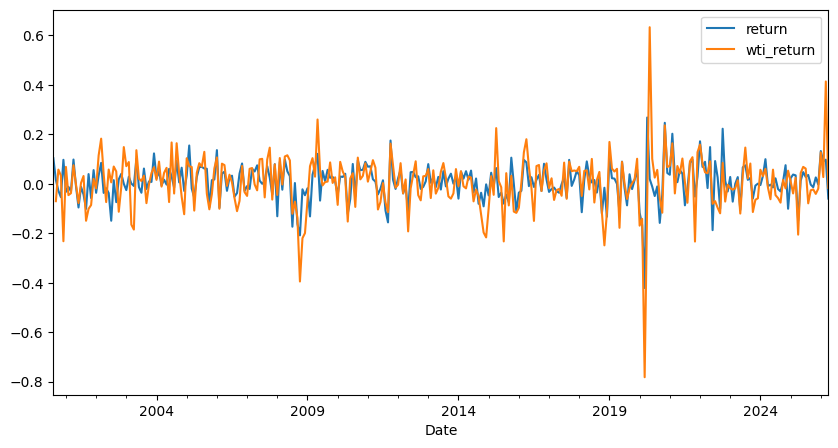

In [309]:
df[["return", "wti_return"]].plot(figsize=(10,5))
plt.savefig("../outputs/charts/xle_vs_oil.png")

In [310]:
sp500 = yf.download("^GSPC", start="1998-01-01")

if isinstance(sp500.columns, pd.MultiIndex):
    sp500.columns = sp500.columns.get_level_values(0)

sp500 = sp500[["Close"]].rename(columns={"Close": "sp500"})
sp500_m = sp500.resample("ME").last()
sp500_m["sp500_return"] = np.log(sp500_m["sp500"]).diff()

df = df.join(sp500_m["sp500_return"], how="inner")

[*********************100%***********************]  1 of 1 completed


In [311]:
X = sm.add_constant(df[["gpr", "wti_return", "sp500_return"]].dropna())
y = df.loc[X.index, "return"]

print(sm.OLS(y, X).fit().summary())

                            OLS Regression Results                            
Dep. Variable:                 return   R-squared:                       0.575
Model:                            OLS   Adj. R-squared:                  0.571
Method:                 Least Squares   F-statistic:                     137.2
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           3.25e-56
Time:                        21:22:34   Log-Likelihood:                 501.68
No. Observations:                 308   AIC:                            -995.4
Df Residuals:                     304   BIC:                            -980.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0035      0.006     -0.547   

In [312]:
# Scenario forecast using final model coefficients

scenario_model = sm.OLS(y, X).fit()

coeffs = scenario_model.params
coeffs

const          -0.003507
gpr             0.000045
wti_return      0.323097
sp500_return    0.751893
dtype: float64

In [313]:
scenarios = pd.DataFrame({
    "scenario": [
        "Bear Case",
        "Base Case",
        "Bull Case",
        "Oil Shock Case",
        "Market Selloff Case"
    ],
    "gpr": [
        df["gpr"].quantile(0.75),   # elevated risk
        df["gpr"].median(),         # normal risk
        df["gpr"].median(),         # normal risk
        df["gpr"].quantile(0.95),   # extreme risk
        df["gpr"].quantile(0.90)    # high risk
    ],
    "wti_return": [
        -0.10,   # oil down 10%
        0.00,    # flat oil
        0.08,    # oil up 8%
        0.15,    # oil up 15%
        -0.05    # oil down 5%
    ],
    "sp500_return": [
        -0.05,   # market down 5%
        0.01,    # market up 1%
        0.04,    # market up 4%
        -0.02,   # risk shock but oil spike
        -0.10    # market selloff
    ]
})

scenarios

,scenario,gpr,wti_return,sp500_return
0,Bear Case,124.461953,-0.10,-0.05
1,Base Case,95.822137,0.00,0.01
2,Bull Case,95.822137,0.08,0.04
3,Oil Shock Case,173.133231,0.15,-0.02
4,Market Selloff Case,152.281550,-0.05,-0.10


In [314]:
# Forecast XLE monthly returns
scenarios["forecast_xle_return"] = (
    coeffs["const"]
    + coeffs["gpr"] * scenarios["gpr"]
    + coeffs["wti_return"] * scenarios["wti_return"]
    + coeffs["sp500_return"] * scenarios["sp500_return"]
)

# Convert to percentage
scenarios["forecast_xle_return_pct"] = scenarios["forecast_xle_return"] * 100

scenarios

,scenario,gpr,wti_return,sp500_return,forecast_xle_return,forecast_xle_return_pct
0,Bear Case,124.461953,-0.10,-0.05,-0.067833,-6.783268
1,Base Case,95.822137,0.00,0.01,0.008307,0.830703
2,Bull Case,95.822137,0.08,0.04,0.056712,5.671159
3,Oil Shock Case,173.133231,0.15,-0.02,0.037680,3.767977
4,Market Selloff Case,152.281550,-0.05,-0.10,-0.088026,-8.802565


In [315]:
scenario_output = scenarios[[
    "scenario",
    "gpr",
    "wti_return",
    "sp500_return",
    "forecast_xle_return_pct"
]].copy()

scenario_output["wti_return"] = scenario_output["wti_return"] * 100
scenario_output["sp500_return"] = scenario_output["sp500_return"] * 100

scenario_output = scenario_output.rename(columns={
    "scenario": "Scenario",
    "gpr": "GPR Level",
    "wti_return": "WTI Return (%)",
    "sp500_return": "S&P 500 Return (%)",
    "forecast_xle_return_pct": "Forecast XLE Return (%)"
})

scenario_output

,Scenario,GPR Level,WTI Return (%),S&P 500 Return (%),Forecast XLE Return (%)
0,Bear Case,124.461953,-10.0,-5.0,-6.783268
1,Base Case,95.822137,0.0,1.0,0.830703
2,Bull Case,95.822137,8.0,4.0,5.671159
3,Oil Shock Case,173.133231,15.0,-2.0,3.767977
4,Market Selloff Case,152.281550,-5.0,-10.0,-8.802565


In [316]:
scenario_output.to_csv("../outputs/tables/xle_scenario_forecast.csv", index=False)

print("Saved scenario forecast to outputs/tables/xle_scenario_forecast.csv")

Saved scenario forecast to outputs/tables/xle_scenario_forecast.csv
